IMPORTING OS, Directing to dataset folder

In [2]:
import os

data_path = "../data"

os.listdir(data_path)

['maven_fuzzy_factory_data_dictionary.csv',
 'orders.csv',
 'order_items.csv',
 'order_item_refunds.csv',
 'products.csv',
 'website_pageviews.csv',
 'website_sessions.csv']

IMPORTING LIBRARIES

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

LOAD DATASET

In [4]:
import pandas as pd

orders = pd.read_csv("../data/orders.csv")

orders.head()

,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


DATA CLEANING PHASE

In [8]:
# Number of rows and columns
orders.shape
#Column names
orders.columns
#Dataset information
orders.info()


<class 'pandas.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  str    
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), str(1)
memory usage: 2.0 MB


In [10]:
#Descriptive statistics
orders.describe()

,order_id,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
count,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000
mean,16157.000000,258292.288707,215691.622629,1.392474,1.238666,59.991636,22.355406
std,9328.103961,132427.649842,108402.203189,0.732277,0.426274,17.808771,6.238621
min,1.000000,20.000000,13.000000,1.000000,1.000000,29.990000,9.490000
25%,8079.000000,144828.000000,124135.000000,1.000000,1.000000,49.990000,19.490000
50%,16157.000000,263554.000000,221461.000000,1.000000,1.000000,49.990000,19.490000
75%,24235.000000,374799.000000,310542.000000,2.000000,1.000000,59.990000,22.490000
max,32313.000000,472818.000000,394273.000000,4.000000,2.000000,109.980000,41.980000


DATA QUALITY CHECKS

In [12]:
# Check missing values
orders.isnull().sum()


order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

In [13]:
# Check duplicate rows
orders.duplicated().sum()

np.int64(0)

In [16]:
# Check numerical summaries
orders[['items_purchased', 'price_usd', 'cogs_usd']].describe()

,items_purchased,price_usd,cogs_usd
count,32313.000000,32313.000000,32313.000000
mean,1.238666,59.991636,22.355406
std,0.426274,17.808771,6.238621
min,1.000000,29.990000,9.490000
25%,1.000000,49.990000,19.490000
50%,1.000000,49.990000,19.490000
75%,1.000000,59.990000,22.490000
max,2.000000,109.980000,41.980000


In [15]:
# Check the date column
orders['created_at'].head()

0    2012-03-19 10:42:46
1    2012-03-19 19:27:37
2    2012-03-20 06:44:45
3    2012-03-20 09:41:45
4    2012-03-20 11:28:15
Name: created_at, dtype: str

In [17]:
orders['created_at'] = pd.to_datetime(orders['created_at'])

orders['created_at'].dtype

dtype('<M8[us]')

In [18]:
orders['year'] = orders['created_at'].dt.year
orders['month'] = orders['created_at'].dt.month
orders['date'] = orders['created_at'].dt.date

orders.head()

,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd,year,month,date
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49,2012,3,2012-03-19
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49,2012,3,2012-03-19
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49,2012,3,2012-03-20
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49,2012,3,2012-03-20
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49,2012,3,2012-03-20


EXPLORATING DATA ANALYSIS PHASE

Revenue, Cost and Profit

In [25]:
# TOTAL REVENUE
total_revenue = orders['price_usd'].sum()

print(f"Total Revenue: ${total_revenue:,.2f}")

# TOTAL COST OF GOODS SOLD (COGS)
total_cogs = orders['cogs_usd'].sum()
print(f"Total COGS: ${total_cogs:,.2f}")

#Gross Profit
gross_profit = total_revenue - total_cogs

print(f"Gross Profit: ${gross_profit:,.2f}")

# Gross Profit Margin
gross_profit_margin = (gross_profit / total_revenue) * 100
print(f"Gross Profit Margin: {gross_profit_margin:.2f}%")

Total Revenue: $1,938,509.75
Total COGS: $722,370.25
Gross Profit: $1,216,139.50
Gross Profit Margin: 62.74%


Monthly Revenue Analysis

In [28]:
monthly_revenue = orders.groupby(
    ['year', 'month']
)['price_usd'].sum().reset_index()

monthly_revenue


,year,month,price_usd
0,2012,3,2999.40
1,2012,4,4949.01
2,2012,5,5398.92
3,2012,6,6998.60
4,2012,7,8448.31
5,2012,8,11397.72
6,2012,9,14347.13
7,2012,10,18546.29
8,2012,11,30893.82
9,2012,12,25294.94


In [29]:
monthly_revenue.loc[
    monthly_revenue['price_usd'].idxmax()
]

year           2014.00
month            12.00
price_usd    144823.02
Name: 33, dtype: float64

VISUALIZE FINDINGS

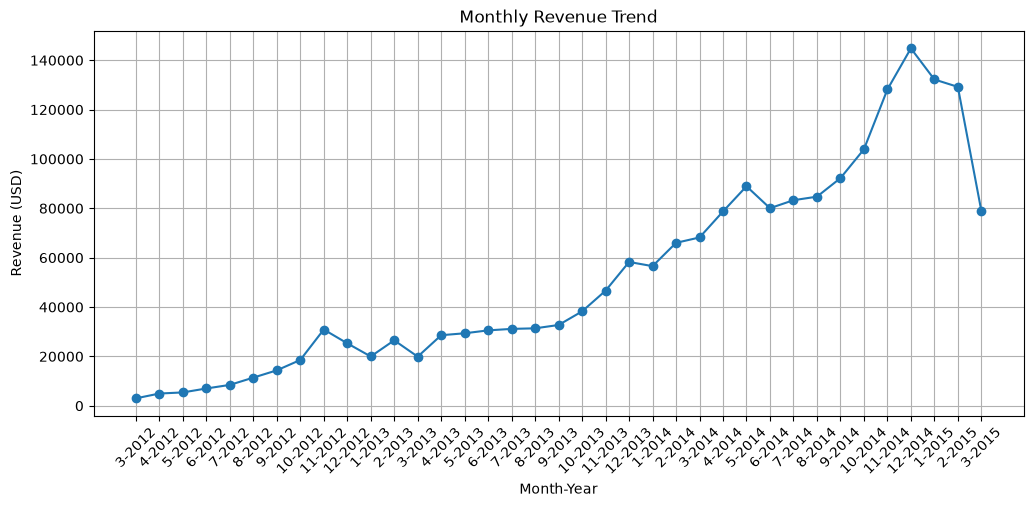

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['month'].astype(str) + '-' + monthly_revenue['year'].astype(str),
    monthly_revenue['price_usd'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month-Year')
plt.ylabel('Revenue (USD)')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

Product Performance Analysis

In [34]:
# LOAD Product dataset

products = pd.read_csv("../data/products.csv")

products.head()

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [35]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    4 non-null      int64
 1   created_at    4 non-null      str  
 2   product_name  4 non-null      str  
dtypes: int64(1), str(2)
memory usage: 228.0 bytes


In [38]:
#See available products
products

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [41]:
#Check product distribution 
orders['primary_product_id'].value_counts()

primary_product_id
1    23861
2     4803
3     3068
4      581
Name: count, dtype: int64

In [43]:
# Check product_revenue
product_revenue = orders.groupby(
    'primary_product_id'
)['price_usd'].sum().reset_index()

product_revenue

,primary_product_id,price_usd
0,1,1419767.82
1,2,318109.18
2,3,180857.03
3,4,19775.72


In [45]:
# Check gross product_profit
product_profit = orders.groupby(
    'primary_product_id'
).agg(
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum')
).reset_index()

product_profit['gross_profit'] = (
    product_profit['revenue'] - product_profit['cogs']
)

product_profit

,primary_product_id,revenue,cogs,gross_profit
0,1,1419767.82,539815.82,879952.0
1,2,318109.18,117761.18,200348.0
2,3,180857.03,58446.53,122410.5
3,4,19775.72,6346.72,13429.0


CUSTOMER ANALYSIS

In [49]:
# Calculate total unique customers
total_customers = orders['user_id'].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 31696


In [51]:
# Average Order Value (AOV)
average_order_value = orders['price_usd'].mean()

print("Average Order Value: $", round(average_order_value, 2))

Average Order Value: $ 59.99


In [52]:
# customers with multiple orders
customer_orders = orders.groupby('user_id')['order_id'].nunique()

repeat_customers = (customer_orders > 1).sum()

print("Repeat Customers:", repeat_customers)

Repeat Customers: 591


WEBSITE CONVERSION ANALYSIS

In [55]:
# Load website sessions data
sessions = pd.read_csv("../data/website_sessions.csv")

sessions.head()

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


In [56]:
# check the number of unique website sessions
total_sessions = sessions['website_session_id'].nunique()

print("Total Website Sessions:", total_sessions)

Total Website Sessions: 472871


In [57]:
# check the number of unique converted sessions
converted_sessions = orders['website_session_id'].nunique()

print("Converted Sessions:", converted_sessions)

Converted Sessions: 32313


In [58]:
# calculate the website conversion rate
conversion_rate = (
    converted_sessions / total_sessions
) * 100

print("Website Conversion Rate:", round(conversion_rate, 2), "%")

Website Conversion Rate: 6.83 %
